In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Project folders
RAW_DIR = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")

# Load cleaned datasets
matches = pd.read_csv(PROCESSED_DIR / "matches_cleaned.csv")
deliveries = pd.read_csv(PROCESSED_DIR / "deliveries_cleaned.csv")
points_table = pd.read_csv(PROCESSED_DIR / "points_table_cleaned.csv")

print("All datasets loaded successfully!")


All datasets loaded successfully!


In [ ]:
print("Matches:", matches.shape)
print("Deliveries:", deliveries.shape)
print("Points Table:", points_table.shape)

Matches: (48, 18)
Deliveries: (26118, 22)
Points Table: (10, 11)


In [ ]:

print("Dataset columns:")
print(matches.columns.tolist())

print("\nFirst 5 matches:")
display(matches.head())

print("\nMatch winners:")
display(matches["winner"].value_counts())

Dataset columns:
['season', 'team1', 'team2', 'date', 'match_number', 'venue', 'city', 'toss_winner', 'toss_decision', 'player_of_match', 'umpire1', 'umpire2', 'reserve_umpire', 'match_referee', 'winner', 'winner_runs', 'winner_wickets', 'match_type']

First 5 matches:


,season,team1,team2,date,match_number,venue,city,toss_winner,toss_decision,player_of_match,umpire1,umpire2,reserve_umpire,match_referee,winner,winner_runs,winner_wickets,match_type
0,2023/24,England,New Zealand,2023-10-05,1,Narendra Modi Stadium,Ahmedabad,New Zealand,field,R Ravindra,HDPK Dharmasena,Nitin Menon,Sharfuddoula,J Srinath,New Zealand,NaN,9.0,Group
1,2023/24,Pakistan,Netherlands,2023-10-06,2,Rajiv Gandhi International Stadium,Hyderabad,Netherlands,field,Saud Shakeel,AT Holdstock,CM Brown,PR Reiffel,JJ Crowe,Pakistan,81.0,NaN,Group
2,2023/24,Afghanistan,Bangladesh,2023-10-07,3,Himachal Pradesh Cricket Association Stadium,Dharamsala,Bangladesh,field,Mehedi Hasan Miraz,JS Wilson,HDPK Dharmasena,M Erasmus,AJ Pycroft,Bangladesh,NaN,6.0,Group
3,2023/24,South Africa,Sri Lanka,2023-10-07,4,Arun Jaitley Stadium,Delhi,Sri Lanka,field,AK Markram,RK Illingworth,Sharfuddoula,AG Wharf,J Srinath,South Africa,102.0,NaN,Group
4,2023/24,Australia,India,2023-10-08,5,MA Chidambaram Stadium,Chennai,Australia,bat,KL Rahul,CB Gaffaney,RA Kettleborough,AT Holdstock,RB Richardson,India,NaN,6.0,Group



Match winners:


winner
India           10
Australia        9
South Africa     7
New Zealand      5
Pakistan         4
Afghanistan      4
England          3
Bangladesh       2
Netherlands      2
Sri Lanka        2
Name: count, dtype: int64

In [23]:
# Q1. How many matches were played in the tournament?
total_matches_played = len(matches)
print("Total matches played:", total_matches_played)


Total matches played: 48


,Team,Total_Wins
0,India,10
1,Australia,9
2,South Africa,7
3,New Zealand,5
4,Pakistan,4
5,Afghanistan,4
6,England,3
7,Bangladesh,2
8,Netherlands,2
9,Sri Lanka,2


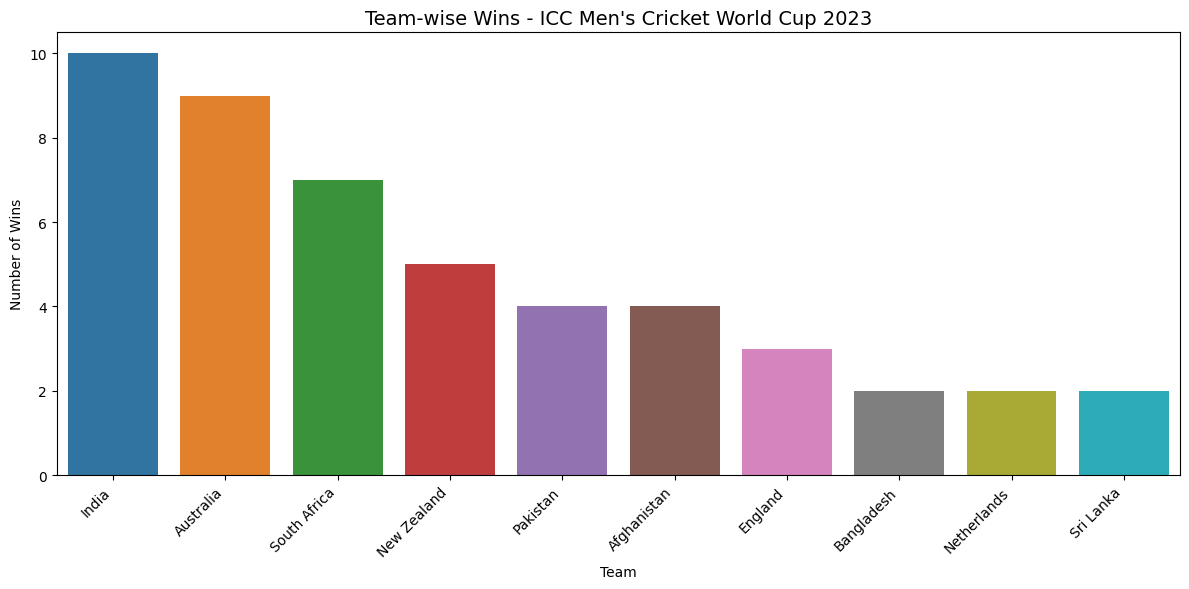

In [41]:
# Q2. Which teams recorded the highest number of wins in the ICC Men's Cricket World Cup 2023?

team_wins = (
    matches["winner"]
    .dropna()
    .value_counts()
    .reset_index()
)

team_wins.columns = ["Team", "Total_Wins"]

team_wins = team_wins.sort_values(
    by="Total_Wins",
    ascending=False
).reset_index(drop=True)

display(team_wins)


plt.figure(figsize=(12, 6))

sns.barplot(
    data=team_wins,
    x="Team",
    y="Total_Wins",
    hue="Team",
    legend=False
    
)

plt.title(
    "Team-wise Wins - ICC Men's Cricket World Cup 2023",
    fontsize=14
)
plt.xlabel("Team")
plt.ylabel("Number of Wins")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

,Toss_Decision,Count,Percentage
0,field,26,54.17
1,bat,22,45.83


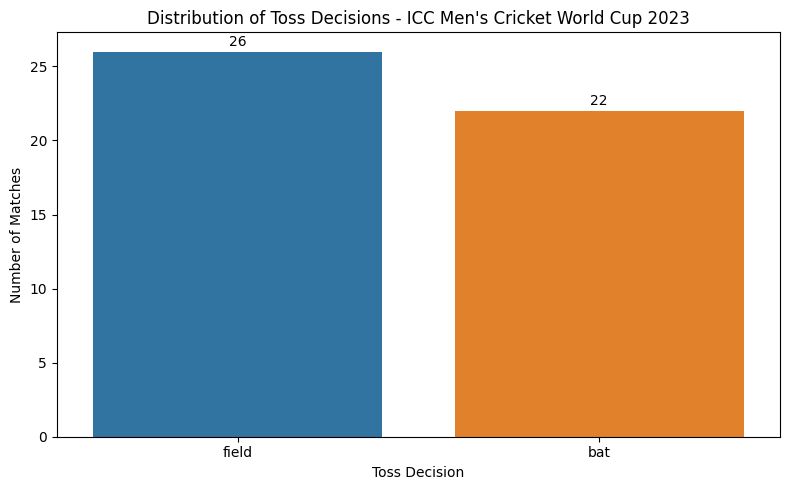

In [54]:
# Q2. What was the distribution of toss decisions between batting first and fielding first?

toss_distribution  = (
    matches["toss_decision"]
    .dropna()
    .value_counts()
    .reset_index()
)
toss_distribution.columns = ["Toss_Decision", "Count"]

# calculate percentage 

total_decisions = toss_distribution["Count"].sum()

toss_distribution["Percentage"] = (
    toss_distribution["Count"] / total_decisions * 100
).round(2)

display(toss_distribution)

plt.figure(figsize=(8,5))

ax = sns.barplot(
    data=toss_distribution,
    x="Toss_Decision",
    y="Count",
    hue="Toss_Decision",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=2)
    
plt.title(
    "Distribution of Toss Decisions - ICC Men's Cricket World Cup 2023"
)
plt.xlabel("Toss Decision")
plt.ylabel("Number of Matches")
plt.tight_layout()
plt.show()

,toss_winner,winner,toss_and_match_winner
0,New Zealand,New Zealand,True
1,Netherlands,Pakistan,False
2,Bangladesh,Bangladesh,True
3,Sri Lanka,South Africa,False
4,Australia,India,False
5,Netherlands,New Zealand,False
6,Bangladesh,England,False
7,Sri Lanka,Pakistan,False
8,Afghanistan,India,False
9,Australia,South Africa,False


Toss-winning team also won the match: 19
Toss-winning team lost the match: 29
Total valid matches: 48

Toss winner also won: 39.58%
Toss winner lost: 60.42%


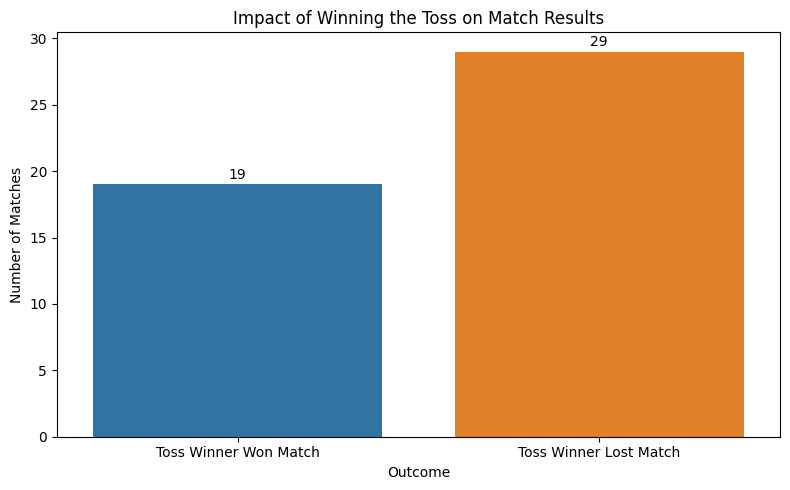

In [73]:
# Q3. How often did the toss-winning team also win the match? 

# Compare toss winner and match winner
matches["toss_and_match_winner"] = (
    matches["toss_winner"] == matches["winner"]
)

display(
    matches[
        ["toss_winner", "winner", "toss_and_match_winner"]
    ].head(10)
)

# calculate the results
valid_matches = matches.dropna(
    subset=["toss_winner", "winner"]
).copy()

toss_won_match = (
    valid_matches["toss_winner"] == valid_matches["winner"]
).sum()

toss_lost_match = len(valid_matches) - toss_won_match

print("Toss-winning team also won the match:", toss_won_match)
print("Toss-winning team lost the match:", toss_lost_match)
print("Total valid matches:", len(valid_matches))

# Calculate percentage

total_matches = len(valid_matches)

win_percentage = round(
    (toss_won_match / total_matches) * 100, 2
)

loss_percentage = round(
    (toss_lost_match / total_matches) * 100, 2
)

print()
print(f"Toss winner also won: {win_percentage}%")
print(f"Toss winner lost: {loss_percentage}%")

result_df = pd.DataFrame({
    "Result": ["Toss Winner Won Match", "Toss Winner Lost Match"],
    "Matches": [toss_won_match, toss_lost_match]
})

plt.figure(figsize=(8,5))

ax = sns.barplot(
    data=result_df,
    x="Result",
    y="Matches",
    hue="Result",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=2)
    
plt.title("Impact of Winning the Toss on Match Results")
plt.xlabel("Outcome")
plt.ylabel("Number of Matches")
plt.tight_layout()
plt.show()

In [76]:
# Q4. Which venues hosted the highest number of matches during the tournament?

matches["venue"].value_counts()

venue
Narendra Modi Stadium                                           5
Himachal Pradesh Cricket Association Stadium                    5
Maharashtra Cricket Association Stadium                         5
Arun Jaitley Stadium                                            5
MA Chidambaram Stadium                                          5
Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium    5
Wankhede Stadium                                                5
M Chinnaswamy Stadium                                           5
Eden Gardens                                                    5
Rajiv Gandhi International Stadium                              3
Name: count, dtype: int64